<a href="https://colab.research.google.com/github/francji1/01ADS/blob/main/lectures/L05_embeddings/01ADS_L05_Embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01ADS - Lecture 05: Embeddings, from images to text

Lecture 04 ended with a pretrained ResNet18 used as a *feature extractor*: remove the classification head and every
image becomes a vector of 512 numbers in which similar images lie close to each other. Such a vector is called an
**embedding**. This lecture follows the same idea further:

- from a network trained on one task to networks trained *only* to produce good embeddings (contrastive learning),
- from images to **images and text in one space** (CLIP), which classifies images it was never trained on,
- from images to **sentences**, which is what search engines and the retrieval part of a RAG system run on,
- from English to **Czech** and to queries in one language finding documents in another.

The running examples are the same CIFAR-10 cats and dogs as in Lecture 04 and a set of questions from Quora with
known duplicates, which lets us *measure* how good a search is, not only look at it.

## Schedule for today's lecture
1. What an embedding is: the ResNet18 vectors from Lecture 04, cosine similarity, normalisation, what a similarity score means in high dimension
2. CLIP, images and text in one space: how it was trained (contrastive loss), zero-shot classification against the fine-tuned networks of Lecture 04, prompts, all ten CIFAR classes, how much labelled data a zero-shot model is worth, search for images by text, a failure (text in the image), your own photo
3. Sentence embeddings: tokens, mean pooling, why a raw language model is not a good embedding model, the length limit
4. Semantic search on Quora: where it sits in a RAG system, keyword search (TF-IDF, BM25) vs. dense vectors, recall@k and MRR, where each one wins, a model that has seen the test data, hybrid search, a similarity threshold as a classifier
5. Czech and multilingual embeddings: an English model on Czech text, a multilingual model, Czech queries on an English corpus
6. Checklist for your project and pointers

Subsections marked *(optional)* (image-to-image neighbours, the gap between images and texts, contextual word
vectors, speed) and the *Your turn* cells can be skipped in the lecture and done at home without losing the thread.

## 0. Setup

**Start with *Runtime → Run all* at the beginning of the lecture.** The first run downloads about 1.4 GB: the
pretrained models from Hugging Face (CLIP about 600 MB, the English sentence model 90 MB, its raw predecessor 90 MB,
the multilingual model 470 MB) and CIFAR-10 (170 MB). A warning about a missing `HF_TOKEN` can be ignored.

Everything runs on a CPU (about 5 minutes in Colab after the downloads). A GPU (*Runtime → Change runtime type → T4
GPU*) only speeds up encoding. The CLIP vectors of about 9 400 CIFAR images were computed once on a GPU and are
downloaded from `outputs/clip_cifar.npz`.

In [1]:
import importlib
import subprocess
import sys

import logging

logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)   # Windows-only notice
for module, package in [("sentence_transformers", "sentence-transformers")]:
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

In [2]:
import os

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import json
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFont
from scipy import sparse
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.neighbors import KNeighborsClassifier
from torchvision import datasets
import transformers
from transformers import AutoModel, AutoTokenizer, CLIPModel, CLIPProcessor
from sentence_transformers import SentenceTransformer

import huggingface_hub

transformers.utils.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
huggingface_hub.utils.logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
torch.manual_seed(SEED)
plt.rcParams["figure.dpi"] = 100
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__}, transformers {transformers.__version__}, device: {device}")

torch 2.9.0+cu128, transformers 5.22.1, device: cuda


In [3]:
# Files of this lecture and of Lecture 04 are read local-first and downloaded from GitHub when missing (Colab).
RAW = "https://raw.githubusercontent.com/francji1/01ADS/main/lectures"
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)


def fetch(relpath: str, lecture: str = "L05_embeddings") -> Path:
    if lecture != "L05_embeddings":
        sibling = Path("..") / lecture / relpath         # the repository is cloned: use the other lecture's folder
        if sibling.exists():
            return sibling
        p = Path(lecture) / relpath
    else:
        p = Path(relpath)
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{RAW}/{lecture}/{relpath}", p)
    return p


L04 = "L04_classification_nn_tl"

## 1. What an embedding is

An **embedding** is a function $f$ that maps an object (an image, a word, a sentence, a user, a product) to a vector
$f(x) \in \mathbb{R}^d$ such that *similar objects get nearby vectors*. Compare it with the one-hot encoding of
categorical variables from Lecture 03: one-hot vectors are as long as the vocabulary, almost all zeros, and every
two different categories are equally far apart. An embedding is short (hundreds of numbers), dense, and its
geometry carries meaning.

Nobody designs the coordinates by hand. They are a by-product of training a network: in Lecture 04 the 512 numbers
were the input of the last layer of ResNet18, which was trained to classify ImageNet. Whatever helps to tell 1 000
classes apart ended up in those numbers.

**Similarity.** The usual measure is the cosine of the angle between two vectors,
$$\cos(u, v) = \frac{u \cdot v}{\lVert u \rVert \, \lVert v \rVert} \in [-1, 1].$$
After normalising every vector to unit length, the cosine is just the dot product, and the squared Euclidean
distance is $\lVert u - v \rVert^2 = 2 - 2\cos(u, v)$, so ranking by distance and ranking by cosine agree. Most
libraries therefore normalise once and then work with dot products, which are a single matrix multiplication.

We start with the vectors Lecture 04 computed: the same CIFAR-10 cats and dogs, the same split, and the ResNet18
embeddings stored in `outputs/embeddings_resnet18.npz` of Lecture 04.

In [4]:
# CIFAR-10 is downloaded by torchvision (170 MB). A local clone reuses the copy of Lecture 04.
DATA_ROOT = Path("..") / L04 / "data" if (Path("..") / L04 / "data" / "cifar-10-batches-py").exists() else Path("data")
cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes
train_targets, test_targets = np.asarray(cifar_train.targets), np.asarray(cifar_test.targets)


def cats_and_dogs(ds):
    # exactly as in Lecture 04: CIFAR-10 labels 3 = cat, 5 = dog; relabelled cat = 0, dog = 1
    targets = np.asarray(ds.targets)
    mask = np.isin(targets, [3, 5])
    return ds.data[mask], (targets[mask] == 5).astype(np.int64), np.flatnonzero(mask)


X_pool, y_pool, _ = cats_and_dogs(cifar_train)
X_test, y_test, cd_test_idx = cats_and_dogs(cifar_test)
rng = np.random.default_rng(SEED)
train_idx = []
for c in (0, 1):
    train_idx += rng.permutation(np.flatnonzero(y_pool == c))[:2000].tolist()   # same 2 000 + 2 000 as Lecture 04
X_train, y_train = X_pool[train_idx], y_pool[train_idx]

z = np.load(fetch("outputs/embeddings_resnet18.npz", L04))
R_train, R_test = z["train"].astype(np.float32), z["test"].astype(np.float32)
print("images:", X_train.shape, X_test.shape, "| ResNet18 embeddings:", R_train.shape, R_test.shape)
print(f"smallest coordinate: {R_train.min():.3f}, mean vector length: {np.linalg.norm(R_train, axis=1).mean():.1f}")

images: (4000, 32, 32, 3) (2000, 32, 32, 3) | ResNet18 embeddings: (4000, 512) (2000, 512)
smallest coordinate: 0.000, mean vector length: 28.2


All coordinates are non-negative: the vector is an average of ReLU outputs. Two consequences, both worth knowing
before reading any similarity score: the cosine of any two such vectors is positive, and the length of the vector
varies from image to image (it says something like "how strongly the features fired", not *what* is in the image).

*Before running: a 10-nearest-neighbour classifier on these vectors, once with Euclidean distance on the raw vectors
and once after normalising them to unit length. Which one is better, and by how much?*

In [5]:
def unit(a):
    a = np.asarray(a, dtype=np.float32)
    return a / np.linalg.norm(a, axis=-1, keepdims=True)


rows = []
for name, A, B in [("raw vectors, Euclidean", R_train, R_test),
                   ("unit vectors (= cosine)", unit(R_train), unit(R_test)),
                   ("centred + unit vectors", unit(R_train - R_train.mean(0)), unit(R_test - R_train.mean(0)))]:
    knn = KNeighborsClassifier(n_neighbors=10).fit(A, y_train)
    rows.append({"model": f"10-NN, {name}", "test accuracy": accuracy_score(y_test, knn.predict(B))})
logreg = LogisticRegression(max_iter=3000).fit(unit(R_train), y_train)
rows.append({"model": "logistic regression, unit vectors", "test accuracy": logreg.score(unit(R_test), y_test)})
pd.DataFrame(rows).round(3)

,model,test accuracy
0,"10-NN, raw vectors, Euclidean",0.842
1,"10-NN, unit vectors (= cosine)",0.856
2,"10-NN, centred + unit vectors",0.856
3,"logistic regression, unit vectors",0.860


Normalising helps a little (the length of the vector is mostly noise for the class), centring (subtracting the mean
training vector before normalising) does not change the neighbours much here, and a linear model is slightly better
than nearest neighbours. The important message is the next one: what values of the cosine are
"high"? The left panel compares pairs of images of the same class with pairs of different classes. The right panel
shows cosines of *random* vectors: in high dimension two random directions are almost perpendicular, so a cosine
of 0.3 between random 512-dimensional vectors would be a very unusual coincidence.

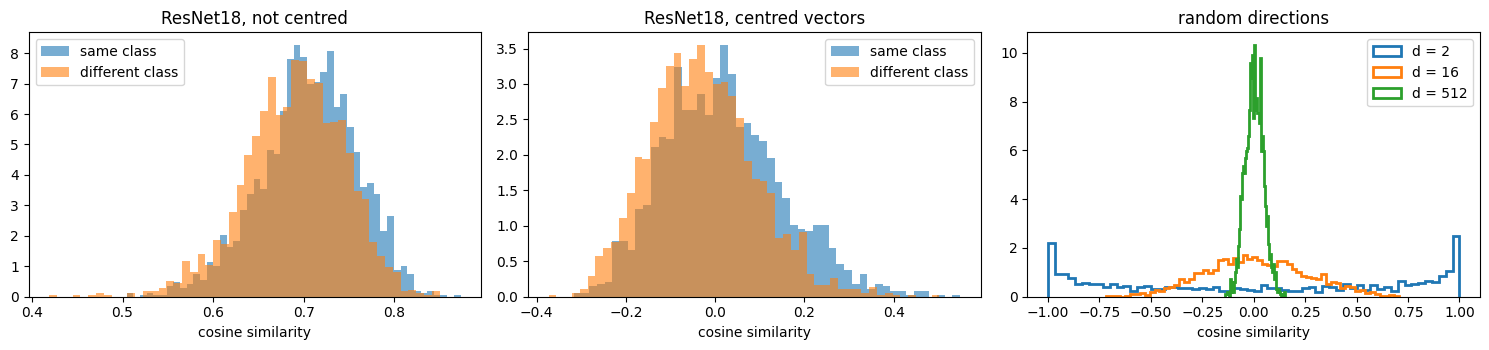

In [6]:
pair_rng = np.random.default_rng(0)
i, j = pair_rng.integers(0, len(R_test), (2, 4000))
i, j = i[i != j], j[i != j]                              # an image paired with itself would add cosines of exactly 1
same = y_test[i] == y_test[j]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (title, E) in zip(axes[:2], [("ResNet18, not centred", unit(R_test)),
                                      ("ResNet18, centred vectors", unit(R_test - R_train.mean(0)))]):
    cos = (E[i] * E[j]).sum(1)
    ax.hist(cos[same], bins=50, alpha=0.6, density=True, label="same class")
    ax.hist(cos[~same], bins=50, alpha=0.6, density=True, label="different class")
    ax.set(title=title, xlabel="cosine similarity")
    ax.legend()
for d in (2, 16, 512):
    G = unit(pair_rng.normal(size=(4000, d)))
    axes[2].hist((G[::2] * G[1::2]).sum(1), bins=60, density=True, histtype="step", lw=2, label=f"d = {d}")
axes[2].set(title="random directions", xlabel="cosine similarity")
axes[2].legend()
plt.tight_layout()
plt.show()

- Without centring, all cosines lie between about 0.5 and 0.9; the two classes overlap a lot and "0.7" means
  nothing on its own. Centring spreads the values out, but the overlap stays.
- A similarity score is meaningful only **relative to other scores of the same model**: ranking candidates works,
  a fixed threshold copied from another model does not. We return to thresholds in Section 4.
- Each model has its own scale. Keep this in mind when somebody reports "similarity 0.62".

## 2. CLIP: images and text in one space

ResNet18 learned its embedding as a side effect of classification into 1 000 fixed classes. **CLIP** (Contrastive
Language–Image Pre-training, Radford et al., 2021) was trained only to produce embeddings, from about 400 million
images with their captions collected from the web. It has two encoders, a vision transformer for images and a text
transformer for captions, each followed by a linear projection to the *same* 512-dimensional space.

<div align="center">

| | image encoder | text encoder |
|---|---|---|
| input | 224×224 image, cut into 32×32 patches | caption, up to 77 tokens |
| network | ViT-B/32 (vision transformer) | 12-layer transformer |
| output | 512 numbers (normalised to unit length) | 512 numbers (normalised to unit length) |

</div>

Training only asks that an image and *its* caption are closer to each other than to every other caption in the
batch. Nothing in the objective mentions classes, yet the result can classify: embed the image, embed the sentences
"a photo of a cat" and "a photo of a dog", and pick the closer sentence. This is **zero-shot classification**: no
labelled training images for our task at all.

In [7]:
CLIP_NAME = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(CLIP_NAME).to(device).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)
n_params = sum(p.numel() for p in clip.parameters())
print(f"{CLIP_NAME}: {n_params / 1e6:.0f} M parameters, temperature exp(logit_scale) = {clip.logit_scale.exp().item():.1f}")


@torch.no_grad()
def clip_text(texts):
    # tokenizer -> text transformer -> projection to the shared space -> unit length
    tok = clip_proc.tokenizer(list(texts), padding=True, truncation=True, return_tensors="pt").to(device)
    feats = clip.text_projection(clip.text_model(**tok).pooler_output)
    return F.normalize(feats, dim=-1).cpu()


@torch.no_grad()
def clip_images(images, batch_size=256):
    # images: uint8 arrays or PIL images; the processor resizes to 224 px and normalises with CLIP statistics
    feats = []
    for k in range(0, len(images), batch_size):
        batch = [Image.fromarray(im) if isinstance(im, np.ndarray) else im.convert("RGB") for im in images[k:k + batch_size]]
        pixels = clip_proc(images=batch, return_tensors="pt")["pixel_values"].to(device)
        feats.append(clip.visual_projection(clip.vision_model(pixel_values=pixels).pooler_output))
    return F.normalize(torch.cat(feats), dim=-1).cpu()

openai/clip-vit-base-patch32: 151 M parameters, temperature exp(logit_scale) = 100.0


### How CLIP was trained: the contrastive loss

Take a batch of $N$ image–caption pairs, embed all images ($u_1, \dots, u_N$) and all captions ($v_1, \dots,
v_N$) and compute all $N \times N$ cosines. The correct pairs sit on the diagonal. Each row is then treated as a
classification problem with $N$ classes ("which caption belongs to this image?") and each column likewise ("which
image belongs to this caption?"):
$$\mathcal{L} = \frac{1}{2}\Big[\mathrm{CE}\big(U V^\top / \tau, \mathrm{diag}\big) + \mathrm{CE}\big(V U^\top / \tau, \mathrm{diag}\big)\Big],$$
where CE is the cross-entropy from Lecture 04 and $\tau$ a learned *temperature*; a small temperature sharpens the
softmax. CLIP learns $\tau \approx 0.01$, stored as the "logit scale" $1/\tau \approx 100$, which is the number the
code multiplies by. This family of objectives is called **InfoNCE** or contrastive loss; the same kind of loss
trains the sentence models of Section 3 (with pairs of sentences instead of image–caption pairs). The batch provides the negatives for free:
CLIP used batches of 32 768 pairs.

Below: eight test images, one per class, with eight captions. We compute the loss by hand and compare it with the
loss the model itself reports.

loss by hand: 0.2010 | reported by the model: 0.2010 | captions shuffled: 4.2913 | random guessing: ln 8 = 2.0794


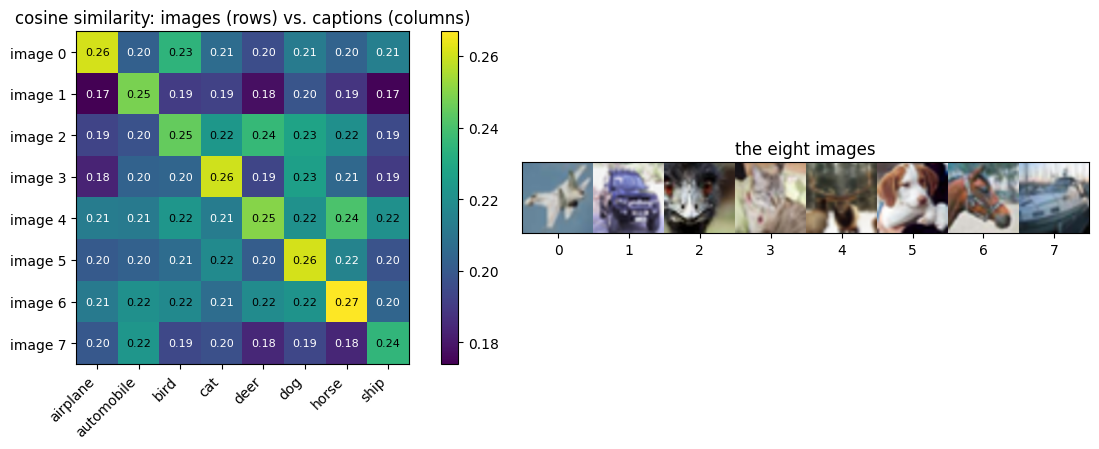

In [8]:
demo_classes = [0, 1, 2, 3, 4, 5, 7, 8]                 # airplane, automobile, bird, cat, deer, dog, horse, ship
demo_idx = [int(np.flatnonzero(test_targets == c)[1]) for c in demo_classes]
demo_images = [cifar_test.data[k] for k in demo_idx]
captions = [f"a photo of a {CIFAR_CLASSES[c]}" for c in demo_classes]

U, V = clip_images(demo_images), clip_text(captions)
scale = clip.logit_scale.exp().item()


def contrastive_loss(U, V, scale):
    logits = scale * U @ V.T
    target = torch.arange(len(U))
    return (F.cross_entropy(logits, target) + F.cross_entropy(logits.T, target)) / 2


with torch.no_grad():
    batch = clip_proc(text=captions, images=[Image.fromarray(im) for im in demo_images], return_tensors="pt", padding=True)
    model_loss = clip(**batch.to(device), return_loss=True).loss.item()
shuffled = contrastive_loss(U, V[torch.randperm(len(V), generator=torch.Generator().manual_seed(1))], scale).item()
print(f"loss by hand: {contrastive_loss(U, V, scale).item():.4f} | reported by the model: {model_loss:.4f} | "
      f"captions shuffled: {shuffled:.4f} | random guessing: ln 8 = {np.log(8):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
S = (U @ V.T).numpy()
im = axes[0].imshow(S, cmap="viridis")
axes[0].set_xticks(range(8), [c.replace("a photo of a ", "") for c in captions], rotation=45, ha="right")
axes[0].set_yticks(range(8), [f"image {k}" for k in range(8)])
for a in range(8):
    for b in range(8):
        axes[0].text(b, a, f"{S[a, b]:.2f}", ha="center", va="center", fontsize=8, color="w" if S[a, b] < S.max() - 0.05 else "k")
axes[0].set_title("cosine similarity: images (rows) vs. captions (columns)")
plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].imshow(np.concatenate([np.asarray(Image.fromarray(im).resize((96, 96))) for im in demo_images], axis=1))
axes[1].set_xticks([48 + 96 * k for k in range(8)], [f"{k}" for k in range(8)])
axes[1].set_yticks([])
axes[1].set_title("the eight images")
plt.tight_layout()
plt.show()

The cosines are small (around 0.2–0.3) and the differences between the right and the wrong caption are a few
hundredths. The logit scale (about 100) turns these small differences into confident probabilities. With shuffled
captions the loss is even higher than random guessing: confidently wrong is worse than not knowing. This also
shows that image–text cosines live on a different scale than image–image cosines; we come back to it with the map
of the embedding space.

### CLIP vectors for the CIFAR images

Encoding about 9 400 images at 224×224 px takes a few seconds on a GPU and ten minutes or more on two CPU cores, so
the vectors were stored once and are downloaded (set `RECOMPUTE_CLIP = True` to encode them yourself): the 4 000
cat/dog training images of Lecture 04, a test set (all 2 000 cats and dogs plus 300 images of each other class) and
100 training images per class for all ten classes.

In [9]:
clip_file = OUT_DIR / "clip_cifar.npz"
RECOMPUTE_CLIP = False                     # True: encode the images again (needs a GPU to be fast)
if not RECOMPUTE_CLIP:
    try:
        fetch(clip_file.as_posix())
    except OSError as e:
        print("download failed, the vectors will be computed:", e)
if RECOMPUTE_CLIP or not clip_file.exists():
    test_idx = np.concatenate([np.flatnonzero(test_targets == c) if c in (3, 5) else np.flatnonzero(test_targets == c)[:300]
                               for c in range(10)])
    rng10 = np.random.default_rng(SEED)
    train10_idx = np.concatenate([rng10.permutation(np.flatnonzero(train_targets == c))[:100] for c in range(10)])
    t0 = time.time()
    np.savez_compressed(clip_file,
                        cd_train=clip_images(list(X_train)).numpy().astype(np.float16),
                        test=clip_images(list(cifar_test.data[test_idx])).numpy().astype(np.float16), test_idx=test_idx,
                        train10=clip_images(list(cifar_train.data[train10_idx])).numpy().astype(np.float16), train10_idx=train10_idx)
    print(f"encoded {4000 + len(test_idx) + len(train10_idx)} images in {time.time() - t0:.1f} s")
z = np.load(clip_file)
C_train = z["cd_train"].astype(np.float32)                      # 4 000 cat/dog training images, same order as R_train
C_test10, test10_idx = z["test"].astype(np.float32), z["test_idx"]
C_train10, train10_idx = z["train10"].astype(np.float32), z["train10_idx"]
y_test10, y_train10 = test_targets[test10_idx], train_targets[train10_idx]
pos = {k: n for n, k in enumerate(test10_idx)}
C_test = C_test10[[pos[k] for k in cd_test_idx]]                 # 2 000 cat/dog test images, same order as R_test
print("CLIP vectors:", C_train.shape, C_test.shape, C_test10.shape, C_train10.shape)

CLIP vectors: (4000, 512) (2000, 512) (4400, 512) (1000, 512)


### Zero-shot: cats vs. dogs without a single training image

*Before running: in Lecture 04 the small CNN trained from scratch reached about 0.72 test accuracy and the fully
fine-tuned ResNet18 about 0.90, both after training on 4 000 labelled images. Where will CLIP land with zero
training images?*

The class "prototype" is the text embedding of a prompt. CLIP was trained on captions, not on single words, so the
prompt matters; a common trick is to average the embeddings of several templates (prompt ensembling).

In [10]:
TEMPLATES = ["a photo of a {}.", "a blurry photo of a {}.", "a low resolution photo of a {}.", "a pixelated photo of a {}.",
             "a photo of the small {}.", "a close-up photo of a {}.", "a photo of my {}.", "an image of a {}."]


def class_prototypes(names, templates):
    protos = [F.normalize(clip_text([t.format(n) for t in templates]).mean(0), dim=0) for n in names]
    return torch.stack(protos).numpy()


def zero_shot(E, prototypes):
    logits = scale * E @ prototypes.T
    p = torch.softmax(torch.tensor(logits), dim=1).numpy()
    return p.argmax(1), p


rows = []
for name, templates in [("bare word: 'cat' / 'dog'", ["{}"]),
                        ("'a photo of a cat.'", ["a photo of a {}."]),
                        (f"ensemble of {len(TEMPLATES)} templates", TEMPLATES)]:
    pred, p = zero_shot(C_test, class_prototypes(["cat", "dog"], templates))
    rows.append({"model": f"CLIP zero-shot, {name}", "labelled training images": 0,
                 "test accuracy": accuracy_score(y_test, pred), "test ROC-AUC": roc_auc_score(y_test, p[:, 1])})
p_zero_cd = p[:, 1]
l04 = json.loads(fetch("outputs/results.json", L04).read_text())
for r in l04:
    rows.append({"model": f"Lecture 04: {r['model']}", "labelled training images": "4000 (+1000 validation)",
                 "test accuracy": r["test accuracy"], "test ROC-AUC": r["test ROC-AUC"]})
pd.DataFrame(rows).round(3)

,model,labelled training images,test accuracy,test ROC-AUC
0,"CLIP zero-shot, bare word: 'cat' / 'dog'",0,0.902,0.975
1,"CLIP zero-shot, 'a photo of a cat.'",0,0.910,0.973
2,"CLIP zero-shot, ensemble of 8 templates",0,0.910,0.973
3,Lecture 04: SimpleCNN from scratch,4000 (+1000 validation),0.724,0.820
4,Lecture 04: (a) ResNet18 frozen + head,4000 (+1000 validation),0.852,0.932
5,Lecture 04: (b) ResNet18 layer4 + head,4000 (+1000 validation),0.897,0.962
6,Lecture 04: (c) ResNet18 full fine-tuning,4000 (+1000 validation),0.904,0.964


CLIP without any cat/dog training image is on par with the best fine-tuned network of Lecture 04, even though the
images are 32×32 px upscaled to 224 px and CLIP never saw this dataset. On this easy two-class task the prompt
matters little (the bare word is slightly worse in accuracy, no worse in ROC-AUC); on harder tasks with many classes, careful prompts and template
ensembles add several percentage points (about 5 on ImageNet in the CLIP paper).

Zero-shot is not free: CLIP has 150 M parameters (ResNet18 has 11 M), was trained on 400 M image–text pairs, and its
inference is slower. For a narrow task with enough labels, a small fine-tuned network is cheaper to run.

### All ten CIFAR classes

Changing the task is now a matter of writing a list of class names. The test set contains 1 000 cats, 1 000 dogs
and 300 images of every other class, so we report balanced accuracy (the mean of per-class recalls).

zero-shot, 10 classes: balanced accuracy 0.896 (chance 0.100)


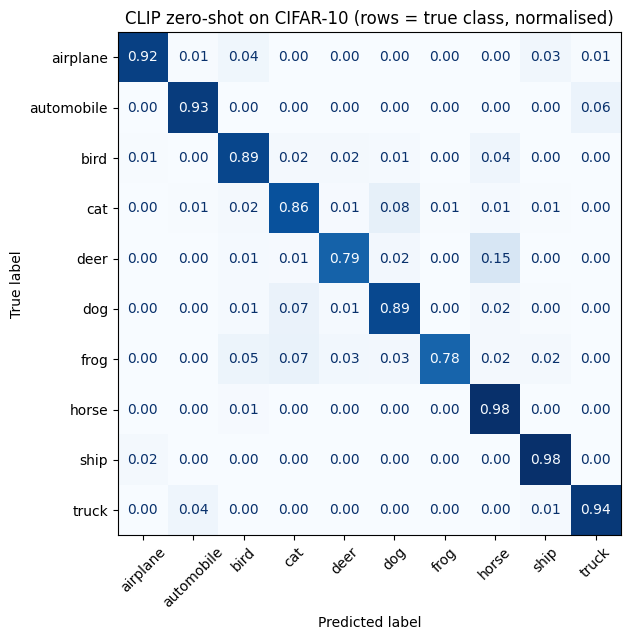

In [11]:
protos10 = class_prototypes(CIFAR_CLASSES, TEMPLATES)
pred10, p10 = zero_shot(C_test10, protos10)
print(f"zero-shot, 10 classes: balanced accuracy {balanced_accuracy_score(y_test10, pred10):.3f} "
      f"(chance 0.100)")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(confusion_matrix(y_test10, pred10, normalize="true"), display_labels=CIFAR_CLASSES).plot(
    ax=ax, cmap="Blues", values_format=".2f", colorbar=False, xticks_rotation=45)
ax.set_title("CLIP zero-shot on CIFAR-10 (rows = true class, normalised)")
plt.tight_layout()
plt.show()

Most mistakes are the human ones: cat ↔ dog, deer → horse, automobile ↔ truck; small blurry frogs also end up as cats
or birds. A class name can also be ambiguous for the text encoder; try `"automobile"` vs. `"car"` in the cell below.

**Your turn:** the cell starts from bare class names. Change one thing at a time (first a class name, then the
template) and watch the balanced accuracy. Can you beat the template ensemble with a single, well-chosen prompt?

In [12]:
my_names = list(CIFAR_CLASSES)        # step 1: replace "automobile" by "car"
my_templates = ["{}"]                 # step 2: try e.g. "a low resolution photo of a {}."
pred_my, _ = zero_shot(C_test10, class_prototypes(my_names, my_templates))
print(f"balanced accuracy with your prompts: {balanced_accuracy_score(y_test10, pred_my):.3f}")

balanced accuracy with your prompts: 0.875


**Zero labels vs. 100 labels per class.** The stored vectors include 100 training images of each of the ten
classes. A logistic regression on their CLIP vectors (1 000 labelled images in total) against the zero-shot
classifier, which used none:

In [13]:
probe10 = LogisticRegression(C=10.0, max_iter=5000).fit(unit(C_train10), y_train10)
print(f"10 classes, balanced accuracy: zero-shot {balanced_accuracy_score(y_test10, pred10):.3f} | "
      f"linear probe on 100 labelled images per class {balanced_accuracy_score(y_test10, probe10.predict(unit(C_test10))):.3f}")

10 classes, balanced accuracy: zero-shot 0.896 | linear probe on 100 labelled images per class 0.932


### How many labelled images is zero-shot worth?

Lecture 04 measured how much data transfer learning saves. The same experiment here: train a logistic regression on
top of frozen embeddings (a *linear probe*) with 1, 2, 5, …, 2 000 labelled images per class, once on ResNet18 vectors
and once on CLIP image vectors, and compare with the zero-shot result that used none.

*Before running: from how many labelled images per class does a linear probe on CLIP vectors beat CLIP's own
zero-shot classifier?*

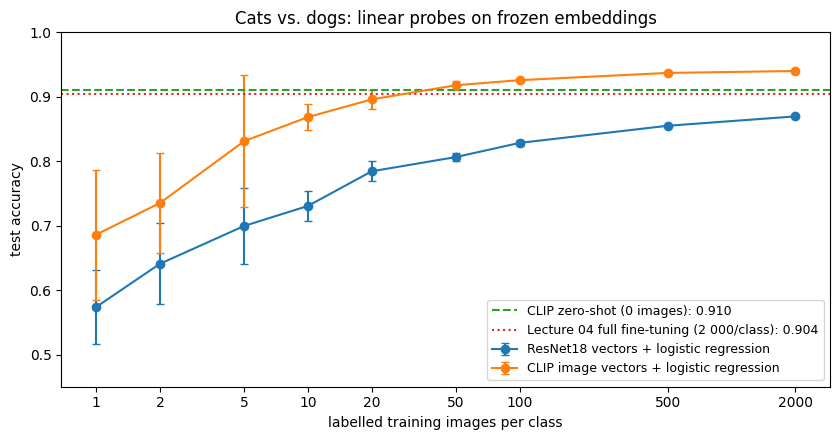

,1,2,5,10,20,50,100,500,2000
ResNet18 vectors + logistic regression,0.574,0.641,0.700,0.731,0.784,0.806,0.828,0.855,0.87
CLIP image vectors + logistic regression,0.686,0.735,0.831,0.868,0.896,0.918,0.926,0.937,0.94


In [14]:
def probe_curve(E_tr, E_te, sizes=(1, 2, 5, 10, 20, 50, 100, 500, 2000), repeats=10):
    E_tr, E_te = unit(E_tr), unit(E_te)
    out = []
    for n in sizes:
        accs = []
        for r in range(repeats if n < 500 else 1):
            g = np.random.default_rng(r)
            idx = np.concatenate([g.choice(np.flatnonzero(y_train == c), n, replace=False) for c in (0, 1)])
            model = LogisticRegression(C=10.0, max_iter=3000).fit(E_tr[idx], y_train[idx])
            accs.append(model.score(E_te, y_test))
        out.append((n, np.mean(accs), np.std(accs)))
    return np.array(out)


curves = {"ResNet18 vectors + logistic regression": probe_curve(R_train, R_test),
          "CLIP image vectors + logistic regression": probe_curve(C_train, C_test)}
zero_acc = accuracy_score(y_test, p_zero_cd > 0.5)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for label, c in curves.items():
    ax.errorbar(c[:, 0], c[:, 1], yerr=c[:, 2], marker="o", capsize=3, label=label)
ax.axhline(zero_acc, color="C2", ls="--", label=f"CLIP zero-shot (0 images): {zero_acc:.3f}")
ax.axhline(l04[-1]["test accuracy"], color="C3", ls=":", label=f"Lecture 04 full fine-tuning (2 000/class): {l04[-1]['test accuracy']:.3f}")
ax.set(xscale="log", xlabel="labelled training images per class", ylabel="test accuracy", ylim=(0.45, 1.0),
       title="Cats vs. dogs: linear probes on frozen embeddings")
sizes = curves[next(iter(curves))][:, 0].astype(int)
ax.set_xticks(sizes, [str(s) for s in sizes])
ax.minorticks_off()
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()
pd.DataFrame({label: c[:, 1] for label, c in curves.items()}, index=curves[next(iter(curves))][:, 0].astype(int)).round(3).T

- With very few labels, the zero-shot classifier wins: one labelled image per class is a noisy estimate of a class,
  while the text prompt summarises everything CLIP learned about cats and dogs.
- A few dozen labelled images per class are enough for the linear probe on CLIP vectors to catch up, and with all
  labels it beats both the zero-shot classifier and the fine-tuned ResNet18 of Lecture 04, without training any
  layer of the network.
- The quality of the embedding sets the ceiling: the same logistic regression on ResNet18 vectors stays well below.
  For your project this is the practical lesson: **the choice of the embedding model often matters more than the
  model you put on top of it**.

### Searching images with text

Since images and texts share one space, a text query can rank images directly: embed the query, take the dot
product with all image vectors, show the best matches. Nothing here was trained on CIFAR or on these queries.

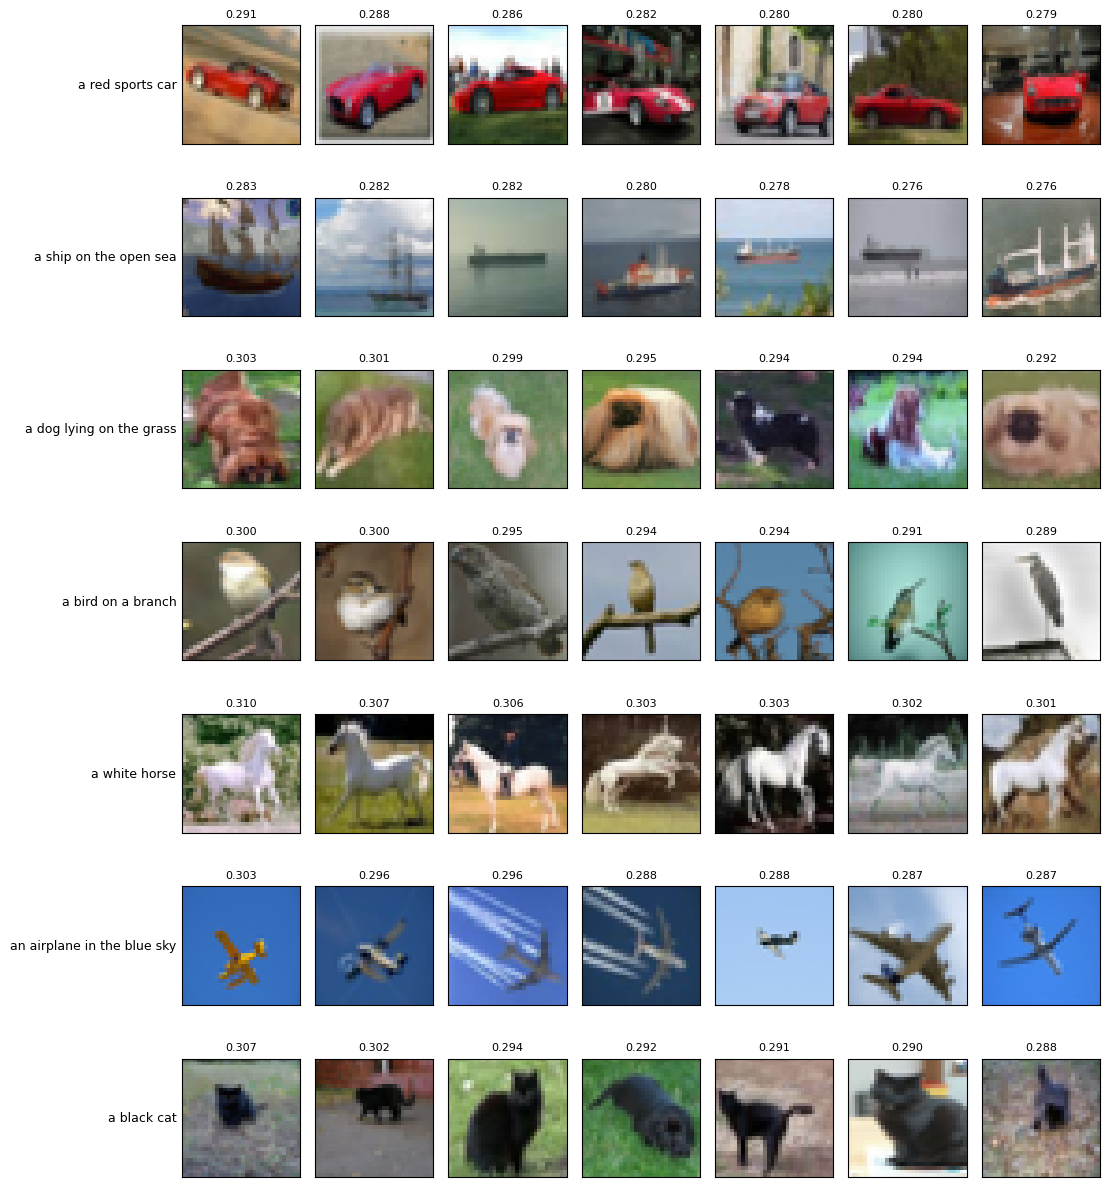

In [15]:
def show_text_search(queries, top=7):
    Q = clip_text(queries).numpy()
    scores = Q @ C_test10.T
    fig, axes = plt.subplots(len(queries), top, figsize=(1.6 * top, 1.75 * len(queries)))
    for r, q in enumerate(queries):
        for c, k in enumerate(np.argsort(-scores[r])[:top]):
            ax = axes[r, c]
            ax.imshow(cifar_test.data[test10_idx[k]], interpolation="nearest")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(f"{scores[r, k]:.3f}", fontsize=8)
        axes[r, 0].set_ylabel(q, rotation=0, ha="right", va="center", fontsize=9)
    plt.tight_layout()
    plt.show()


show_text_search(["a red sports car", "a ship on the open sea", "a dog lying on the grass", "a bird on a branch",
                  "a white horse", "an airplane in the blue sky", "a black cat"])

**Your turn:** write your own queries. Colours, backgrounds and poses work surprisingly well; counting ("three
dogs") and negation ("a dog that is not brown") do not, because CLIP was trained to match captions, not to reason
about them.

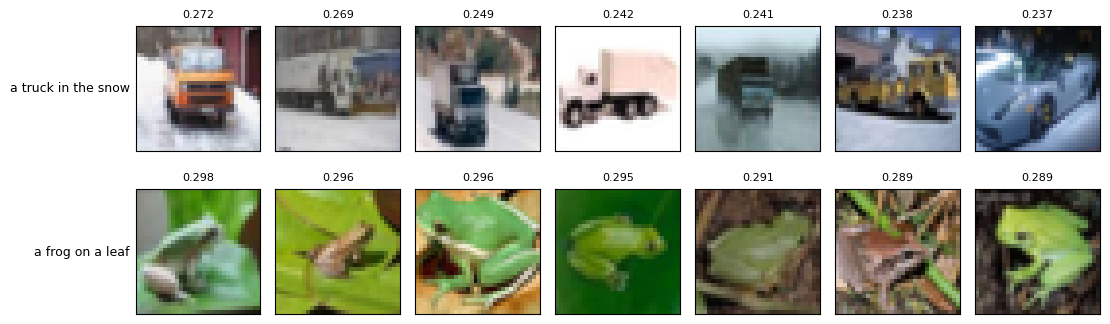

In [16]:
show_text_search(["a truck in the snow", "a frog on a leaf"], top=7)

### Image-to-image search: ResNet18 vs. CLIP neighbours (optional)

Lecture 04 showed nearest neighbours in the ResNet18 embedding. The same query images, neighbours by ResNet18 and by
CLIP (both by cosine; the first image in each row is the query).

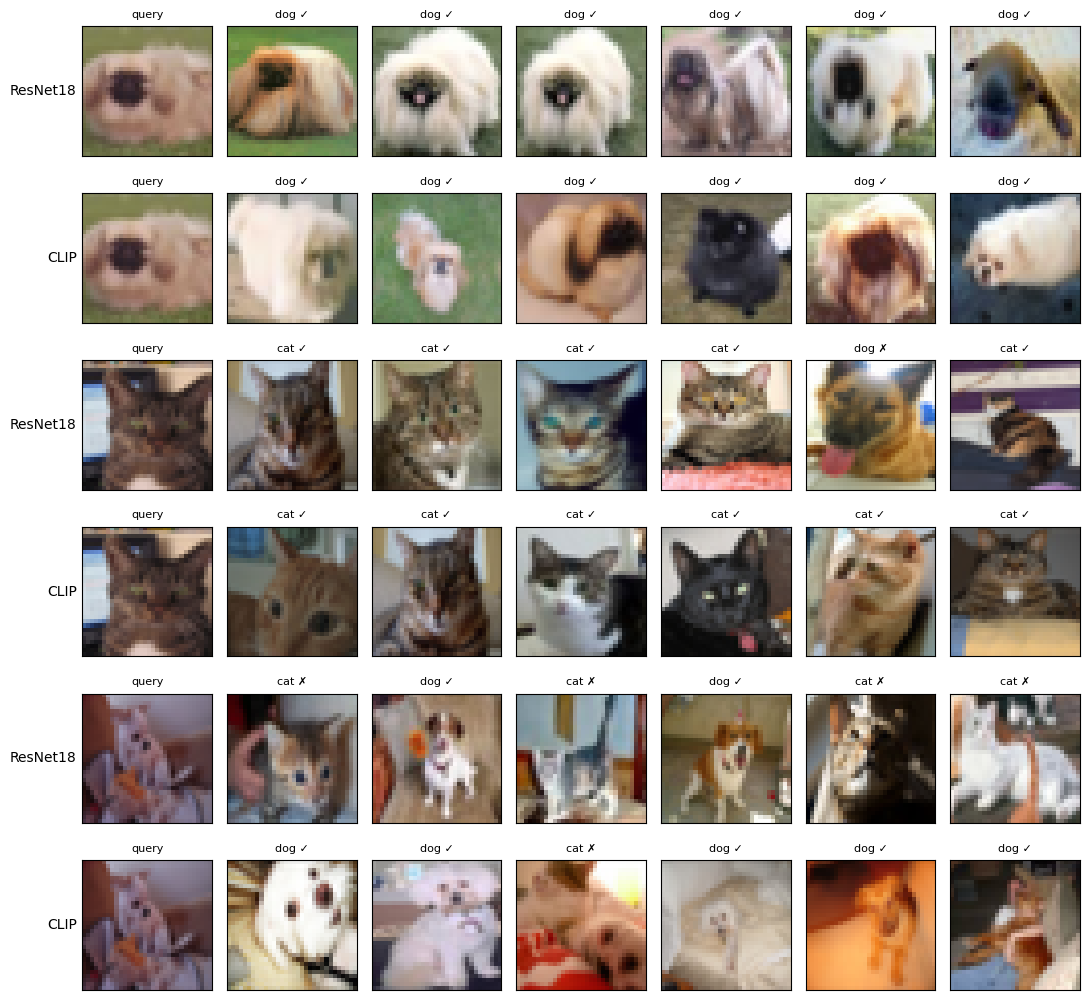

share of the 10 nearest neighbours with the same class (500 queries): ResNet18 0.748, CLIP 0.855


In [17]:
def neighbours(E, q, k=6):
    E = unit(E)
    return np.argsort(-(E @ E[q]))[1:k + 1]


queries_img = [5, 120, 1503]
fig, axes = plt.subplots(2 * len(queries_img), 7, figsize=(11, 3.4 * len(queries_img)))
for r, q in enumerate(queries_img):
    for s, (name, E) in enumerate([("ResNet18", R_test), ("CLIP", C_test)]):
        row = axes[2 * r + s]
        row[0].imshow(X_test[q], interpolation="nearest")
        row[0].set_title("query", fontsize=8)
        row[0].set_ylabel(name, rotation=0, ha="right", va="center")
        for c, k in enumerate(neighbours(E, q), start=1):
            row[c].imshow(X_test[k], interpolation="nearest")
            row[c].set_title(("dog" if y_test[k] else "cat") + (" ✓" if y_test[k] == y_test[q] else " ✗"), fontsize=8)
        for ax in row:
            ax.set_xticks([])
            ax.set_yticks([])
plt.tight_layout()
plt.show()
nn_agree = {name: np.mean([np.mean(y_test[neighbours(E, q, 10)] == y_test[q]) for q in range(0, 2000, 4)])
            for name, E in [("ResNet18", R_test), ("CLIP", C_test)]}
print("share of the 10 nearest neighbours with the same class (500 queries): "
      + ", ".join(f"{k} {v:.3f}" for k, v in nn_agree.items()))

### A failure: text in the image

CLIP learned from captions written by people, and captions often describe text that is visible in the photo. The
model therefore learned to *read*, which can be turned against it (Goh et al., 2021, "typographic attacks"): a label
written on the object can outweigh the object itself. The middle panel is the control: the same white box without
the word, so that we know it is the word, not the hidden muzzle, that changes the answer.

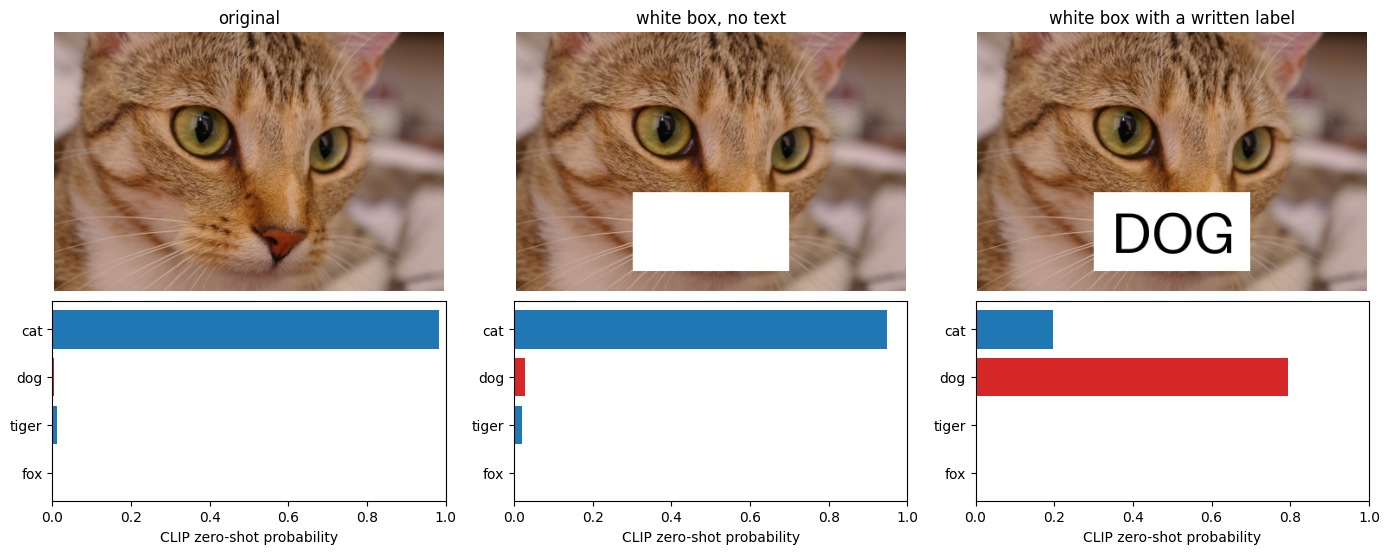

In [18]:
def clip_probs(image, labels, template="a photo of a {}."):
    E = clip_images([image]).numpy()
    return zero_shot(E, class_prototypes(labels, [template]))[1][0]


def get_font(size):
    try:
        return ImageFont.load_default(size=size)                  # Pillow >= 10.1
    except TypeError:
        return ImageFont.load_default()


def with_label(img, text):
    out = img.copy()
    draw = ImageDraw.Draw(out)
    w, h = out.size
    draw.rectangle([w * 0.30, h * 0.62, w * 0.70, h * 0.92], fill="white")
    if text:
        font = get_font(int(h * 0.22))
        try:
            draw.text((w * 0.5, h * 0.77), text, fill="black", font=font, anchor="mm")
        except ValueError:                                          # old Pillow bitmap font: no anchor support
            draw.text((w * 0.42, h * 0.72), text, fill="black", font=font)
    return out


cat_img = Image.open(fetch("pics/chelsea.png", L04)).convert("RGB")
labels = ["cat", "dog", "tiger", "fox"]
fig, axes = plt.subplots(2, 3, figsize=(14, 5.6), gridspec_kw={"height_ratios": [1.3, 1]})
for c, (img, title) in enumerate([(cat_img, "original"), (with_label(cat_img, ""), "white box, no text"),
                                  (with_label(cat_img, "DOG"), "white box with a written label")]):
    p = clip_probs(img, labels)
    axes[0, c].imshow(img)
    axes[0, c].set_title(title)
    axes[0, c].axis("off")
    axes[1, c].barh(labels, p, color=["C0" if l != "dog" else "C3" for l in labels])
    axes[1, c].set(xlim=(0, 1), xlabel="CLIP zero-shot probability")
    axes[1, c].invert_yaxis()
plt.tight_layout()
plt.show()

The same weakness applies to every system built on such embeddings: an image search for "dog" will happily return
a poster with the word "dog" on it, and a document retriever can be steered by text planted in a document. Models
inherit the shortcuts and the biases of their training data, and web captions are a very uneven teacher.

### The map: images and texts are not mixed (optional)

One space does not mean one cloud. Project the image vectors and the prompt vectors to two dimensions with PCA:

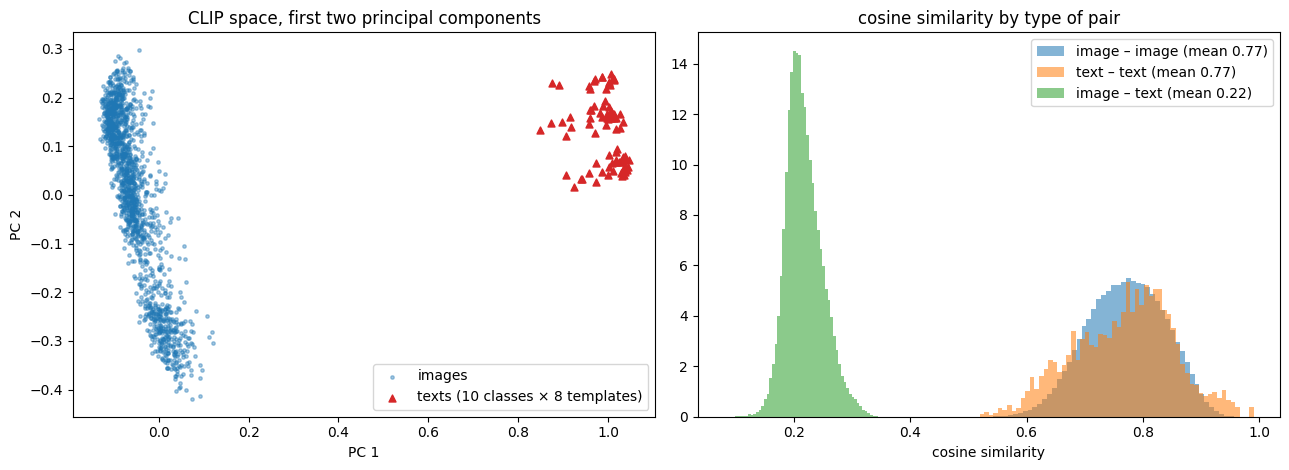

In [19]:
img_sample = C_test10[np.random.default_rng(0).choice(len(C_test10), 1500, replace=False)]
txt_vecs = torch.cat([clip_text([t.format(n) for t in TEMPLATES]) for n in CIFAR_CLASSES]).numpy()
pca = PCA(2).fit(np.vstack([img_sample, txt_vecs]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
P_img, P_txt = pca.transform(img_sample), pca.transform(txt_vecs)
axes[0].scatter(*P_img.T, s=6, alpha=0.4, label="images")
axes[0].scatter(*P_txt.T, s=25, marker="^", color="C3", label="texts (10 classes × 8 templates)")
axes[0].set(title="CLIP space, first two principal components", xlabel="PC 1", ylabel="PC 2")
axes[0].legend()
cos_ii = (img_sample[:500] @ img_sample[500:1000].T).ravel()
cos_tt = (txt_vecs @ txt_vecs.T)[np.triu_indices(len(txt_vecs), 1)]
cos_it = (img_sample @ txt_vecs.T).ravel()
for vals, name in [(cos_ii, "image – image"), (cos_tt, "text – text"), (cos_it, "image – text")]:
    axes[1].hist(vals, bins=60, density=True, alpha=0.55, label=f"{name} (mean {vals.mean():.2f})")
axes[1].set(title="cosine similarity by type of pair", xlabel="cosine similarity")
axes[1].legend()
plt.tight_layout()
plt.show()

The first principal component separates the two modalities almost perfectly: images occupy one region, texts
another (the *modality gap*, Liang et al., 2022). Zero-shot classification still works because only the *ranking*
of texts for a given image matters, and within the text region the class directions are arranged consistently with
the images. Practical consequence: never compare an image–text score with an image–image score.

### Your own photo

The cell accepts a URL, a local file or a PIL image and any list of labels. In Colab you can upload a file with the
folder icon on the left and pass its name.

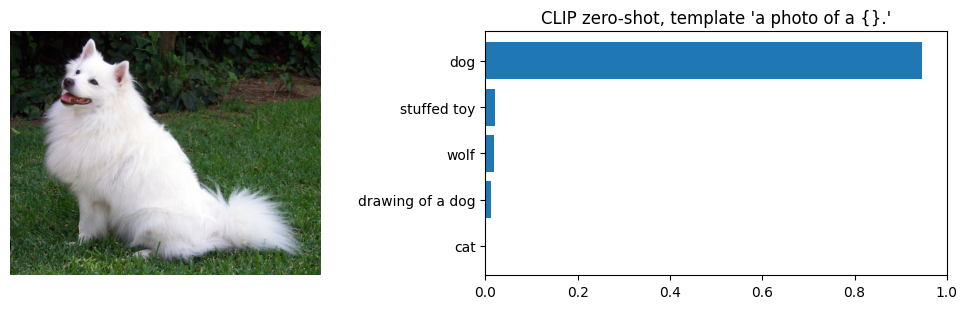

In [20]:
def explain_clip(source, labels, template="a photo of a {}."):
    if isinstance(source, Image.Image):
        img = source
    elif str(source).startswith("http"):
        req = urllib.request.Request(source, headers={"User-Agent": "Mozilla/5.0 (01ADS lecture notebook)"})
        with urllib.request.urlopen(req) as r:
            img = Image.open(r).convert("RGB")
            img.load()
    else:
        img = Image.open(source).convert("RGB")
    p = clip_probs(img, labels, template)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1, 1.3]})
    axes[0].imshow(img)
    axes[0].axis("off")
    order = np.argsort(p)
    axes[1].barh(np.array(labels)[order], p[order])
    axes[1].set(xlim=(0, 1), title=f"CLIP zero-shot, template '{template}'")
    plt.tight_layout()
    plt.show()


explain_clip(fetch("pics/dog.jpg", L04), ["dog", "cat", "wolf", "stuffed toy", "drawing of a dog"])

## 3. Sentence embeddings

For a search engine or a RAG system we need one vector per *piece of text*: a question, a paragraph, a document
chunk. The standard tool are sentence-embedding models from the `sentence-transformers` library. We use
`all-MiniLM-L6-v2`: 6 transformer layers, 22 M parameters, 384-dimensional vectors, fast on a CPU. What happens
inside, in three steps:

1. **Tokenisation.** The text is split into sub-word tokens from a fixed vocabulary (about 30 000 for this model);
   rare words are cut into pieces marked `##`. Lecture 07 covers tokenisers properly.
2. **Contextual token vectors.** The transformer turns every token into a vector that depends on the whole
   sentence (attention, again Lecture 07).
3. **Pooling.** The token vectors are averaged (mean pooling, padding excluded) and normalised to unit length.

In [21]:
ST_NAME = "sentence-transformers/all-MiniLM-L6-v2"
st_model = SentenceTransformer(ST_NAME, device=str(device))
tok = AutoTokenizer.from_pretrained(ST_NAME)
enc_model = AutoModel.from_pretrained(ST_NAME).to(device).eval()

sentence = "Embeddings turn unbelievably messy questions into vectors."
ids = tok(sentence)["input_ids"]
print(len(ids), "tokens:", tok.convert_ids_to_tokens(ids))
dim = getattr(st_model, "get_embedding_dimension", None) or st_model.get_sentence_embedding_dimension
print(f"max input length: {st_model.max_seq_length} tokens, vector size: {dim()}")

17 tokens: ['[CLS]', 'em', '##bed', '##ding', '##s', 'turn', 'un', '##bel', '##ie', '##va', '##bly', 'messy', 'questions', 'into', 'vectors', '.', '[SEP]']
max input length: 256 tokens, vector size: 384


**Contextual vectors** *(optional)*. Lecture 06 trains word2vec, which gives one vector per word regardless of context. A
transformer gives a different vector for each occurrence. The word *bank* in three sentences:

In [22]:
@torch.no_grad()
def token_vectors(texts, model=enc_model, tokenizer=tok):
    batch = tokenizer(texts, padding=True, truncation=True, return_tensors="pt").to(device)
    return batch, model(**batch).last_hidden_state.cpu()


bank_sentences = ["We sat on the bank of the river and watched the boats.",
                  "The grassy bank of the stream was full of flowers.",
                  "I opened a savings account at the bank last week."]
batch, H = token_vectors(bank_sentences)
bank_id = tok.convert_tokens_to_ids("bank")
vecs = torch.stack([H[s, (batch["input_ids"][s].cpu() == bank_id).nonzero()[0, 0]] for s in range(3)])
pd.DataFrame(F.normalize(vecs, dim=1) @ F.normalize(vecs, dim=1).T, index=[s[:40] + "…" for s in bank_sentences],
             columns=["river 1", "river 2", "money"]).round(3)

,river 1,river 2,money
We sat on the bank of the river and watc…,1.000,0.883,0.716
The grassy bank of the stream was full o…,0.883,1.000,0.638
I opened a savings account at the bank l…,0.716,0.638,1.000


All three vectors still carry the identity of the word *bank*, so even the "money" occurrence keeps a fairly high
cosine with the "river" ones. The context shows in the *relative* values: the two river banks are clearly closer
to each other than to the bank with the savings account.

**Mean pooling by hand** gives the same vector as the library (the library only adds the normalisation step):

In [23]:
def mean_pool(batch, H):
    mask = batch["attention_mask"].cpu().unsqueeze(-1).float()
    return F.normalize((H * mask).sum(1) / mask.sum(1), dim=-1)


examples = ["How can I learn Python quickly?", "What is the fastest way to master Python?", "How do I bake bread without yeast?"]
by_hand = mean_pool(*token_vectors(examples))
library = st_model.encode(examples, convert_to_tensor=True, normalize_embeddings=True).cpu()
print("largest difference between the two:", (by_hand - library).abs().max().item())

largest difference between the two: 3.725290298461914e-08


### Why not use any language model?

The library model was produced in two stages: a general-purpose MiniLM language model (distilled from a large
masked language model, never trained for similarity), and then contrastive fine-tuning on about one billion pairs of
related texts (question–answer, title–abstract, duplicate questions, …) with the same kind of loss as in Section 2
(in-batch negatives; `MultipleNegativesRankingLoss` in sentence-transformers, which by default scores in one
direction only, query → document, with a fixed scale of 20 instead of a learned temperature). The raw pretrained
model is available too
(`nreimers/MiniLM-L6-H384-uncased`), so we can compare *the same architecture* before and after the contrastive
stage, with the same mean pooling.

*Before running: two unrelated Quora questions. What cosine do you expect from the raw language model, and what from
the model fine-tuned for similarity?*

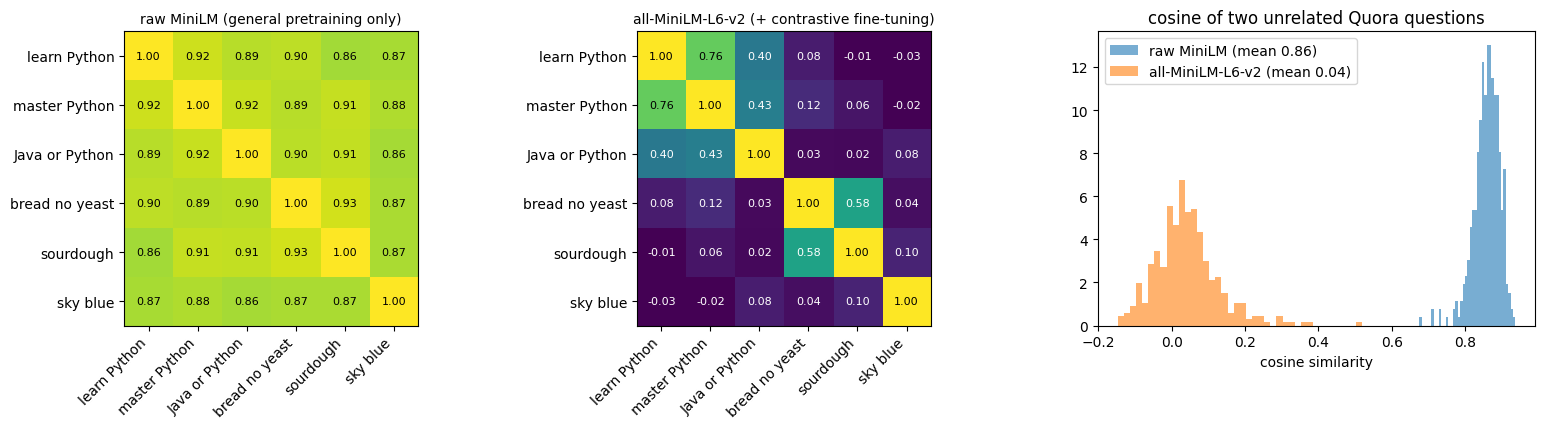

In [24]:
RAW_NAME = "nreimers/MiniLM-L6-H384-uncased"
raw_tok = AutoTokenizer.from_pretrained(RAW_NAME)
raw_model = AutoModel.from_pretrained(RAW_NAME).to(device).eval()
sents = ["How can I learn Python quickly?", "What is the fastest way to master Python?",
         "Is Java or Python better for web development?", "How do I bake bread without yeast?",
         "What is a good recipe for sourdough bread?", "Why is the sky blue?"]
E_raw = mean_pool(*token_vectors(sents, raw_model, raw_tok)).numpy()
E_st = st_model.encode(sents, normalize_embeddings=True)

pairs_df = pd.read_csv(fetch("data/quora_pairs.csv"))
rnd = pairs_df.sample(400, random_state=0)
cos_rand = {}
for name, enc in [("raw MiniLM", lambda t: mean_pool(*token_vectors(t, raw_model, raw_tok)).numpy()),
                  ("all-MiniLM-L6-v2", lambda t: st_model.encode(t, normalize_embeddings=True))]:
    a = np.vstack([enc(rnd.question1.tolist()[k:k + 100]) for k in range(0, 400, 100)])
    b = np.vstack([enc(rnd.question2.sample(frac=1, random_state=1).tolist()[k:k + 100]) for k in range(0, 400, 100)])
    cos_rand[name] = (a * b).sum(1)                              # question1 vs. a random, unrelated question2

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.1]})
short = ["learn Python", "master Python", "Java or Python", "bread no yeast", "sourdough", "sky blue"]
for ax, (name, E) in zip(axes[:2], [("raw MiniLM (general pretraining only)", E_raw), ("all-MiniLM-L6-v2 (+ contrastive fine-tuning)", E_st)]):
    S = E @ E.T
    ax.imshow(S, vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(6), short, rotation=45, ha="right")
    ax.set_yticks(range(6), short)
    for a in range(6):
        for b in range(6):
            ax.text(b, a, f"{S[a, b]:.2f}", ha="center", va="center", fontsize=8, color="w" if S[a, b] < 0.6 else "k")
    ax.set_title(name, fontsize=10)
for name, v in cos_rand.items():
    axes[2].hist(v, bins=40, alpha=0.6, density=True, label=f"{name} (mean {v.mean():.2f})")
axes[2].set(title="cosine of two unrelated Quora questions", xlabel="cosine similarity")
axes[2].legend()
plt.tight_layout()
plt.show()

Without the contrastive stage, everything is similar to everything (the vectors fill a narrow cone, Ethayarajh,
2019): two unrelated questions have a cosine around 0.85, and the related pairs barely stand out. After contrastive
fine-tuning, unrelated texts drop close to zero and the structure of the matrix appears. Lesson: an embedding model
is a model *trained for similarity*; the hidden states of an arbitrary language model are not a substitute.

### The length limit

Every model has a maximum input length (256 tokens here, about 150–200 English words; 128 tokens for the
multilingual model of Section 5). Everything beyond it is **silently cut off**. Moreover, this model was fine-tuned
on texts of at most 128 tokens, so the quality drops even before the hard limit:

In [25]:
filler = " ".join(["The faculty building has four floors and a large lecture hall on the ground floor."] * 25)
key_fact = "The final exam of the course takes place on Friday 15 January in room B-314."
docs_len = {"key fact only": key_fact, "key fact, then filler": key_fact + " " + filler, "filler, then key fact": filler + " " + key_fact}
q = st_model.encode("When is the final exam?", normalize_embeddings=True)
for name, d in docs_len.items():
    n_tok = len(tok(d)["input_ids"])
    print(f"{name:<24} {n_tok:>4} tokens, model sees {min(n_tok, st_model.max_seq_length):>3}   "
          f"cosine with the query: {st_model.encode(d, normalize_embeddings=True) @ q:.3f}")

key fact only              20 tokens, model sees  20   cosine with the query: 0.794
key fact, then filler     420 tokens, model sees 256   cosine with the query: 0.520
filler, then key fact     420 tokens, model sees 256   cosine with the query: 0.220


When the fact sits after the limit, the document vector does not contain it at all; when it sits at the start of a
long document, it is diluted by the rest. This is why RAG systems split documents into **chunks** of a few hundred
tokens before embedding them (Lecture 08).

## 4. Semantic search on Quora

This section is the retrieval half of the RAG system you are building:

```
offline:  documents ──► chunks ──► embedding model ──► vectors (index)
online:   question ──► embedding model ──► query vector ──► top-k most similar chunks ──► language model ──► answer
                                                            └──────── measured here ────────┘
```

If the right chunk is not among the top $k$, the language model cannot use it, however good it is. So we build a
search engine in miniature and *measure* it: a **corpus** of 10 000 Quora questions and 1 000 **queries**. Each query
has between one and five duplicates in the corpus (questions that Quora's moderators marked as asking the same thing,
or linked through a chain of such pairs), and these are the documents we want to find. The rest of the corpus are
unrelated questions. For every query we rank the whole corpus and check where the relevant documents ended up.

The file `data/quora_retrieval.csv` was cut from the Quora Question Pairs dataset (404 000 labelled pairs); duplicate
labels were made by people and are incomplete, so some "wrong" hits are in fact duplicates nobody labelled.

**A caveat to keep in mind for the whole section.** Quora duplicate questions are part of the training data of
`all-MiniLM-L6-v2` (its model card lists about 100 000 Quora triplets), and the multilingual model of Section 5 was
distilled from a model trained on them too. The dense model has seen pairs like these during training; BM25 has
not seen anything. The comparison below therefore *favours* the dense model, and on your own documents you should
expect lower numbers. A public benchmark that leaked into a model's training data is the retrieval version of the
data leakage from Lecture 03, and the main reason why you need a test set made from your own data.

**Symmetric vs. asymmetric search.** Quora is *symmetric*: a question is matched against other questions of
similar length and style. In your project a short question has to find a longer passage that *answers* it, often
written in a different style ("Kolikrát můžu opakovat zkoušku?" → "Zkoušku lze opakovat nejvýše dvakrát…"). That
is harder, it is why some models use different prefixes for queries and passages, and it is why your test set
should consist of real question → passage pairs.

In [26]:
ret = pd.read_csv(fetch("data/quora_retrieval.csv"))
queries = ret[ret.role == "query"].reset_index(drop=True)
corpus = ret[ret.role == "corpus"].reset_index(drop=True)
relevant = [np.flatnonzero(corpus.group.values == g) for g in queries.group]
print(f"{len(queries)} queries, {len(corpus)} documents, {sum(map(len, relevant))} relevant documents "
      f"({np.mean([len(r) for r in relevant]):.2f} per query)")
for k in (1, 5, 11):
    print(f"\nquery: {queries.text[k]}")
    for d in relevant[k]:
        print(f"   relevant: {corpus.text[d]}")

1000 queries, 10000 documents, 1275 relevant documents (1.27 per query)

query: How can I make a perfect BBQ steak?
   relevant: What makes a perfect steak?

query: What is the best university degree for data science, and at which university?
   relevant: What are the best schools for a degree in data science?

query: How can I find and approach venture capitalists or VCs?
   relevant: How do I Approach a venture capitalist?


### Three retrievers

- **TF-IDF** (bag of words): a document is a sparse vector with one coordinate per word of the vocabulary; the weight
  of a word is its count times $\log(N/\mathrm{df})$, where $N$ is the number of documents and $\mathrm{df}$ the number
  of documents containing the word, so words that occur everywhere count little (scikit-learn uses a smoothed
  variant and, with `sublinear_tf=True`, $1 + \log$ of the count). Similarity is the cosine of these vectors. Only
  exact word matches count.
- **BM25** (Okapi BM25, 1994; the default ranking in Lucene and Elasticsearch): also word matching, with a
  term-frequency saturation ($k_1$) and a document-length correction ($b$). Ten lines with a sparse matrix:
  $$\text{BM25}(q, d) = \sum_{w \in q} \mathrm{idf}(w)\, \frac{\mathrm{tf}(w, d)\,(k_1 + 1)}{\mathrm{tf}(w, d) + k_1\big(1 - b + b\,|d| / \overline{|d|}\big)},
  \qquad \mathrm{idf}(w) = \log\Big(1 + \frac{N - \mathrm{df}(w) + 0.5}{\mathrm{df}(w) + 0.5}\Big),$$
  where $\mathrm{tf}(w, d)$ is the count of word $w$ in document $d$ and $|d|$ the length of the document in words.
- **Dense retrieval:** embed every document once with `all-MiniLM-L6-v2`, embed the query, rank by dot product.

In [27]:
class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.vec = CountVectorizer(token_pattern=r"(?u)\b\w+\b")
        tf = self.vec.fit_transform(docs).tocoo().astype(np.float64)        # documents x words, raw counts
        n_docs, df = tf.shape[0], np.bincount(tf.col, minlength=tf.shape[1])
        idf = np.log(1 + (n_docs - df + 0.5) / (df + 0.5))
        dl = np.asarray(tf.sum(1)).ravel()
        weight = tf.data * (k1 + 1) / (tf.data + k1 * (1 - b + b * dl[tf.row] / dl.mean())) * idf[tf.col]
        self.W = sparse.csr_matrix((weight, (tf.row, tf.col)), shape=tf.shape)

    def scores(self, texts):
        q = self.vec.transform(texts)
        q.data[:] = 1.0                                                       # each query word counts once
        return (q @ self.W.T).toarray()


t0 = time.time()
tfidf = TfidfVectorizer(sublinear_tf=True).fit(corpus.text)
S_tfidf = (tfidf.transform(queries.text) @ tfidf.transform(corpus.text).T).toarray()
S_bm25 = BM25(corpus.text).scores(queries.text)
print(f"TF-IDF + BM25: {time.time() - t0:.1f} s")

t0 = time.time()
D_st = st_model.encode(corpus.text.tolist(), batch_size=128, normalize_embeddings=True)
Q_st = st_model.encode(queries.text.tolist(), batch_size=128, normalize_embeddings=True)
print(f"dense: encoded {len(D_st) + len(Q_st)} texts in {time.time() - t0:.1f} s on {device}")
S_dense = Q_st @ D_st.T

TF-IDF + BM25: 0.6 s


dense: encoded 11000 texts in 1.8 s on cuda


### Measuring a search

For a query with relevant documents $R$ and the ranked list returned by the retriever:

- **Recall@k**: the share of $R$ found among the top $k$ results. In RAG, recall@k with $k$ = number of chunks passed
  to the language model is the number that matters most: what is not retrieved cannot be used.
- **Hit@1**: the share of queries whose top result is relevant. Note that with several relevant documents recall@1
  cannot reach 1 (one slot, two duplicates); its maximum for this data is printed below.
- **MRR@10** (mean reciprocal rank): $1/\text{rank}$ of the first relevant result (0 if it is not in the top 10),
  averaged over queries. It rewards putting a relevant result at the very top.

*Before running: will BM25 or the dense model win, and by how much in recall@10?*

In [28]:
def ranks_of_relevant(S, relevant):
    # rank (1 = best) of every relevant document for every query
    order = np.argsort(-S, axis=1)
    pos = np.empty_like(order)
    pos[np.arange(len(S))[:, None], order] = np.arange(S.shape[1])[None, :] + 1
    return [pos[q, r] for q, r in enumerate(relevant)]


def evaluate(S, name, ks=(1, 5, 10, 100)):
    rk = ranks_of_relevant(S, relevant)
    row = {"retriever": name}
    for k in ks:
        row[f"recall@{k}"] = np.mean([np.mean(r <= k) for r in rk])
    first = np.array([r.min() for r in rk])
    row["hit@1"] = np.mean(first == 1)
    row["MRR@10"] = np.mean(np.where(first <= 10, 1 / first, 0))
    return row, first


print(f"largest possible recall@1 on this data: {np.mean([1 / len(r) for r in relevant]):.3f}")
results, first_rank = [], {}
for name, S in [("TF-IDF", S_tfidf), ("BM25", S_bm25), ("dense (all-MiniLM-L6-v2)", S_dense)]:
    row, first_rank[name] = evaluate(S, name)
    results.append(row)
pd.DataFrame(results).set_index("retriever").round(3)

largest possible recall@1 on this data: 0.897


,recall@1,recall@5,recall@10,recall@100,hit@1,MRR@10
retriever,,,,,,
TF-IDF,0.829,0.970,0.984,0.997,0.922,0.949
BM25,0.837,0.967,0.980,0.996,0.931,0.952
dense (all-MiniLM-L6-v2),0.884,0.996,1.000,1.000,0.986,0.992


The task is easy: both keyword retrievers and the dense model put a duplicate first for more than 90 % of the
queries, because duplicate questions usually share several words and the other questions in the corpus are
unrelated. Dense retrieval is better on every measure, with the caveat above (it was trained on this kind of data).
The differences come from a few dozen harder queries, and they are more instructive than the averages.

In [29]:
scores_by_name = {"BM25": S_bm25, "dense (all-MiniLM-L6-v2)": S_dense}


def show_disagreement(winner, loser, n=4):
    gain = first_rank[loser] - first_rank[winner]
    for q in np.argsort(-gain)[:n]:
        top = np.argmax(scores_by_name[loser][q])
        best_rel = relevant[q][np.argmax(scores_by_name[winner][q, relevant[q]])]   # the one the winner ranked first
        print(f"query:      {queries.text[q]}")
        print(f"relevant:   {corpus.text[best_rel]}")
        print(f"            rank {first_rank[winner][q]} with {winner}, rank {first_rank[loser][q]} with {loser}")
        print(f"{loser} top-1: {corpus.text[top]}\n")


print("=== dense finds it, BM25 does not ===\n")
show_disagreement("dense (all-MiniLM-L6-v2)", "BM25")
print("=== BM25 finds it, dense does not ===\n")
show_disagreement("BM25", "dense (all-MiniLM-L6-v2)")

=== dense finds it, BM25 does not ===

query:      Which is the best way to download movies?
relevant:   How can I download movie?
            rank 1 with dense (all-MiniLM-L6-v2), rank 273 with BM25
BM25 top-1: Which is the best way to learn assembly language?

query:      Which is the best site to learn coding online for beginners?
relevant:   What is the best website to learn code as a beginner?
            rank 1 with dense (all-MiniLM-L6-v2), rank 88 with BM25
BM25 top-1: Which is best book to learn R-programming for beginners?

query:      What can I do to become more wise?
relevant:   How do you become wiser in life?
            rank 1 with dense (all-MiniLM-L6-v2), rank 70 with BM25
BM25 top-1: What can I do to be more conversable?

query:      What is the best way to learn discipline?
relevant:   How do I develop discipline?
            rank 1 with dense (all-MiniLM-L6-v2), rank 68 with BM25
BM25 top-1: What is the best way to learn webmethods tool?

=== BM25 finds it, dense d

Typical pattern: dense vectors handle paraphrases and synonyms (different words, same meaning), keyword search
handles rare exact terms, names, numbers and codes (*IIIT-H*, *lateral entry*), which a small embedding model maps to
a vague "general topic" vector. Read the second list critically too: some "relevant" documents are questionable
duplicates (the label noise mentioned above), and there the dense model's top hit is arguably the better answer.
Note also the asymmetry in the ranks: when BM25 fails, the relevant question is far down its list (rank 68–273
in the examples above); when the dense model "fails", it is still in its top 10 (rank 2–7). The two kinds of errors
are different, which suggests combining the retrievers.

### Hybrid search: reciprocal rank fusion

Scores of BM25 and cosines are on incomparable scales, so instead of adding scores we add *ranks*:
$\text{RRF}(d) = \sum_{\text{retrievers}} 1 / (60 + \text{rank}(d))$ (Cormack et al., 2009). Most vector databases
offer this as "hybrid search".

*Before running: can combining two retrievers be worse than the better one alone?*

In [30]:
def rrf(*score_matrices, k=60, depth=100):
    fused = np.zeros_like(score_matrices[0])
    rows = np.arange(len(fused))[:, None]
    for S in score_matrices:
        top = np.argsort(-S, axis=1)[:, :depth]
        fused[rows, top] += 1.0 / (k + np.arange(1, depth + 1))[None, :]
    return fused


row, first_rank["hybrid"] = evaluate(rrf(S_bm25, S_dense), "hybrid: BM25 + dense (RRF)")
results.append(row)
pd.DataFrame(results).set_index("retriever").round(3)

,recall@1,recall@5,recall@10,recall@100,hit@1,MRR@10
retriever,,,,,,
TF-IDF,0.829,0.970,0.984,0.997,0.922,0.949
BM25,0.837,0.967,0.980,0.996,0.931,0.952
dense (all-MiniLM-L6-v2),0.884,0.996,1.000,1.000,0.986,0.992
hybrid: BM25 + dense (RRF),0.874,0.987,0.994,1.000,0.975,0.984


On Quora the hybrid is *slightly worse* than dense retrieval alone. Rank fusion gives both retrievers an equal vote,
and here BM25 is the weaker one: the queries are short paraphrases, exactly where dense vectors are strong, and the
dense model was trained on Quora pairs, so BM25 adds more noise than rescues. On technical documents full of names, abbreviations, course codes or part numbers the
balance often tips the other way. Hybrid search is therefore something to **measure on your own data**, not a
guaranteed improvement.

**Your turn:** search the corpus with your own question. Compare what the keyword and the dense retriever return.

In [31]:
bm25 = BM25(corpus.text)


def search(query, top=5):
    s_dense = st_model.encode(query, normalize_embeddings=True) @ D_st.T
    s_bm25 = bm25.scores([query])[0]
    out = pd.DataFrame({"dense": [f"{s_dense[k]:.3f}  {corpus.text[k]}" for k in np.argsort(-s_dense)[:top]],
                        "BM25": [f"{s_bm25[k]:.1f}  {corpus.text[k]}" for k in np.argsort(-s_bm25)[:top]]})
    with pd.option_context("display.max_colwidth", 90):
        display(out)


search("Which programming language should a beginner learn first?")

,dense,BM25
0,0.919 Which programming languages should I start learning?,"22.9 Which Programming Language Should I Learn, C# Or C++?"
1,0.870 What is the best programming language one should start with?,21.9 What is the first programming languange to learn for a total beginner?
2,0.869 What is the first programming languange to learn for a total beginner?,19.8 Which programming Languages should I learn?
3,0.854 Which programming Languages should I learn?,17.9 Which backend programming language is the best to learn and why?
4,0.833 What is the programming language to learn?,17.8 What is the programming language to learn?


### A similarity threshold is a classifier

Search ranks; deduplication or "is there an answer in the knowledge base at all?" needs a decision: cosine above a
threshold means duplicate. That is a binary classifier with one feature, and Lecture 04's tools apply directly. We use
3 000 labelled pairs from the same dataset (38 % duplicates).

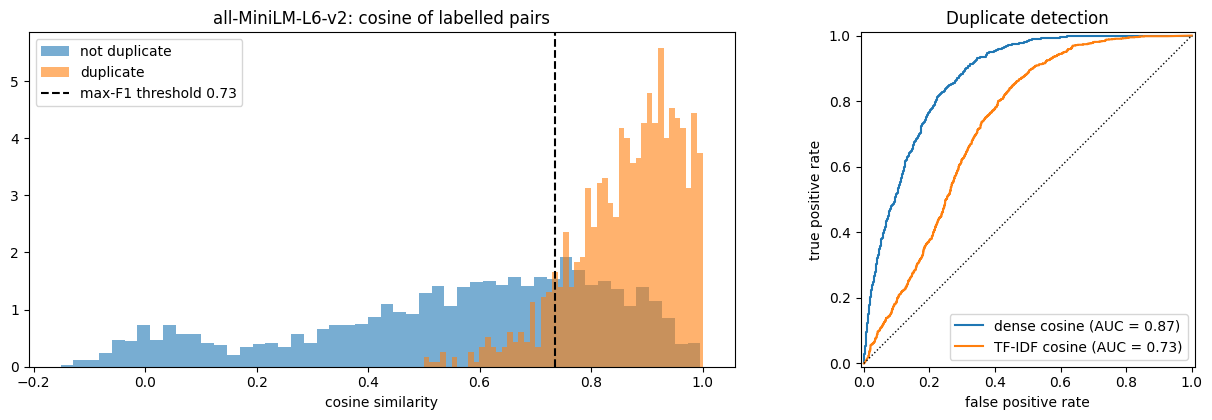

ROC-AUC: dense 0.871, TF-IDF 0.729 | max F1 = 0.748 at cosine >= 0.73


In [32]:
a = st_model.encode(pairs_df.question1.tolist(), batch_size=128, normalize_embeddings=True)
b = st_model.encode(pairs_df.question2.tolist(), batch_size=128, normalize_embeddings=True)
cos_pairs = (a * b).sum(1)
tfidf_pairs = np.asarray((tfidf.transform(pairs_df.question1).multiply(tfidf.transform(pairs_df.question2))).sum(1)).ravel()
y_pairs = pairs_df.is_duplicate.values

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].hist(cos_pairs[y_pairs == 0], bins=50, alpha=0.6, density=True, label="not duplicate")
axes[0].hist(cos_pairs[y_pairs == 1], bins=50, alpha=0.6, density=True, label="duplicate")
grid = np.linspace(0, 1, 201)
f1s = [f1_score(y_pairs, cos_pairs >= t) for t in grid]
best_t = grid[int(np.argmax(f1s))]
axes[0].axvline(best_t, color="k", ls="--", label=f"max-F1 threshold {best_t:.2f}")
axes[0].set(title="all-MiniLM-L6-v2: cosine of labelled pairs", xlabel="cosine similarity")
axes[0].legend()
RocCurveDisplay.from_predictions(y_pairs, cos_pairs, ax=axes[1], name="dense cosine")
RocCurveDisplay.from_predictions(y_pairs, tfidf_pairs, ax=axes[1], name="TF-IDF cosine")
axes[1].plot([0, 1], [0, 1], "k:", lw=1)
axes[1].set(title="Duplicate detection", xlabel="false positive rate", ylabel="true positive rate")
plt.tight_layout()
plt.show()
print(f"ROC-AUC: dense {roc_auc_score(y_pairs, cos_pairs):.3f}, TF-IDF {roc_auc_score(y_pairs, tfidf_pairs):.3f} | "
      f"max F1 = {max(f1s):.3f} at cosine >= {best_t:.2f}")

The two histograms overlap substantially. Partly the model, partly the labels: Quora's pairs were selected to be
hard (most non-duplicates are on the same topic), and the "duplicate" label reflects moderators' judgement. Dense
cosines still separate the classes far better than TF-IDF cosines (compare the two AUCs), with the same caveat as
above: these pairs come from the dataset the model was fine-tuned on, so the dense AUC is optimistic. The best threshold (printed
above) holds for *this* model and *this* kind of text only; with another model, or with long
paragraphs instead of questions, it has to be estimated again on labelled data, exactly like the decision threshold
in Lecture 04. (For brevity the threshold was chosen and scored on the same pairs, so the printed F1 is optimistic;
in a real application choose it on a validation part and report the F1 on the rest.)

### Speed (optional)

Dense search is a matrix–vector product of the document matrix with the query vector. A search application answers
one query at a time, so each query reads the whole matrix; a batch of queries shares that cost and is much faster
per query.

In [33]:
t0 = time.time()
for _ in range(5):
    np.argpartition(-(Q_st @ D_st.T), 10, axis=1)[:, :10]
dt_batch = (time.time() - t0) / 5 / len(Q_st)
t0 = time.time()
for qv in Q_st[:200]:
    np.argpartition(-(D_st @ qv), 10)[:10]
dt_one = (time.time() - t0) / 200
print(f"{len(D_st)} documents: {dt_one * 1e3:.2f} ms per query one at a time, {dt_batch * 1e3:.3f} ms per query in a batch of {len(Q_st)}")
for n_docs in (1e5, 1e6, 1e7):
    print(f"{n_docs:>12,.0f} documents: {n_docs * 384 * 4 / 1e9:6.2f} GB of float32 vectors, "
          f"about {dt_one * n_docs / len(D_st) * 1e3:7.1f} ms per query by brute force")

10000 documents: 0.47 ms per query one at a time, 0.131 ms per query in a batch of 1000
     100,000 documents:   0.15 GB of float32 vectors, about     4.7 ms per query by brute force
   1,000,000 documents:   1.54 GB of float32 vectors, about    47.2 ms per query by brute force
  10,000,000 documents:  15.36 GB of float32 vectors, about   472.3 ms per query by brute force


Brute force is perfectly fine up to hundreds of thousands of documents (a few milliseconds per query; the
extrapolation is rough, real timings depend on the hardware and on memory bandwidth). Beyond that, *approximate nearest neighbour*
indexes (FAISS, HNSW in vector databases) trade a little recall for orders of magnitude in speed; that, together with
chunking and connecting the retriever to a language model, is Lecture 08.

## 5. Czech and multilingual embeddings

Your project documents are mostly in Czech. `all-MiniLM-L6-v2` was trained on English only: its uncased tokenizer even
strips the diacritics, chops Czech words into many meaningless pieces, and the vectors carry little meaning. Multilingual models were trained so that a
sentence and its translation get the same vector (Reimers & Gurevych, 2020: a multilingual student model learns to
imitate an English teacher model on parallel sentences). We use
`paraphrase-multilingual-MiniLM-L12-v2` (50+ languages including Czech, 118 M parameters, 384-dimensional vectors,
input limit 128 tokens).

In [34]:
ML_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
ml_model = SentenceTransformer(ML_NAME, device=str(device))
for text in ["Přijímací řízení na fakultu", "Admission procedure at the faculty"]:
    print(f"{text!r}\n   English model:      {tok.tokenize(text)}\n   multilingual model: {ml_model.tokenizer.tokenize(text)}")

'Přijímací řízení na fakultu'
   English model:      ['pri', '##jima', '##ci', 'ri', '##zen', '##i', 'na', 'fa', '##ku', '##lt', '##u']
   multilingual model: ['▁Při', 'jí', 'ma', 'cí', '▁řízení', '▁na', '▁fakult', 'u']
'Admission procedure at the faculty'
   English model:      ['admission', 'procedure', 'at', 'the', 'faculty']
   multilingual model: ['▁Ad', 'mission', '▁procedure', '▁at', '▁the', '▁fac', 'ul', 'ty']


A small mixed Czech/English collection on student topics, and Czech questions. For every query we show the best
document according to each model.

In [35]:
docs_cs_en = [
    "Zápis do dalšího semestru probíhá elektronicky v informačním systému fakulty.",
    "Zkoušku lze opakovat nejvýše dvakrát, opravné termíny vypisuje vyučující.",
    "Studenti mohou požádat o stipendium na studijní pobyt v zahraničí.",
    "Kolej nabízí dvoulůžkové pokoje, menza je v přízemí sousední budovy.",
    "Kvantová mechanika popisuje chování částic pomocí vlnové funkce.",
    "Knihovna má ve zkouškovém období prodlouženou otevírací dobu až do 22 hodin.",
    "Diplomovou práci je nutné odevzdat v elektronické podobě do termínu stanoveného harmonogramem.",
    "International students must register their stay with the foreign police within 30 days of arrival.",
    "Erasmus grants cover part of the living costs during an exchange semester abroad.",
    "The cafeteria accepts payment by student ID card or by bank card.",
    "Nuclear reactors use controlled fission chain reactions to produce heat.",
    "Credits are awarded after passing the exam or obtaining the course assessment.",
    "Scientific journals can be accessed from home through the university VPN.",
    "The thesis defence is public and takes about thirty minutes.",
]
queries_cs = ["Jak se přihlásit na výměnný pobyt v cizině?", "Kolikrát můžu dělat zkoušku znovu?",
              "Kde se dá najíst?", "Jak funguje jaderný reaktor?", "Jak se dostanu k odborným článkům z domova?",
              "Jak dlouho trvá obhajoba diplomky?"]

table = []
for name, model in [("all-MiniLM-L6-v2 (English)", st_model), ("multilingual MiniLM", ml_model)]:
    S = model.encode(queries_cs, normalize_embeddings=True) @ model.encode(docs_cs_en, normalize_embeddings=True).T
    for qi, qtext in enumerate(queries_cs):
        best = int(np.argmax(S[qi]))
        table.append({"query": qtext, "model": name, "score": round(float(S[qi, best]), 3), "best document": docs_cs_en[best]})
with pd.option_context("display.max_colwidth", 110):
    display(pd.DataFrame(table).sort_values(["query", "model"]).set_index(["query", "model"]))

score  \
query                                       model                               
Jak dlouho trvá obhajoba diplomky?          all-MiniLM-L6-v2 (English)  0.510   
                                            multilingual MiniLM         0.569   
Jak funguje jaderný reaktor?                all-MiniLM-L6-v2 (English)  0.551   
                                            multilingual MiniLM         0.732   
Jak se dostanu k odborným článkům z domova? all-MiniLM-L6-v2 (English)  0.570   
                                            multilingual MiniLM         0.407   
Jak se přihlásit na výměnný pobyt v cizině? all-MiniLM-L6-v2 (English)  0.551   
                                            multilingual MiniLM         0.583   
Kde se dá najíst?                           all-MiniLM-L6-v2 (English)  0.378   
                                            multilingual MiniLM         0.287   
Kolikrát můžu dělat zkoušku znovu?          all-MiniLM-L6-v2 (English)  0.592   
                                            multilingual MiniLM         0.683   

                                                                                                                                                         best document  
query                                       model                                                                                                                       
Jak dlouho trvá obhajoba diplomky?          all-MiniLM-L6-v2 (English)  Diplomovou práci je nutné odevzdat v elektronické podobě do termínu stanoveného harmonogramem.  
                                            multilingual MiniLM                                           The thesis defence is public and takes about thirty minutes.  
Jak funguje jaderný reaktor?                all-MiniLM-L6-v2 (English)                            Kolej nabízí dvoulůžkové pokoje, menza je v přízemí sousední budovy.  
                                            multilingual MiniLM                               Nuclear reactors use controlled fission chain reactions to produce heat.  
Jak se dostanu k odborným článkům z domova? all-MiniLM-L6-v2 (English)                       Zkoušku lze opakovat nejvýše dvakrát, opravné termíny vypisuje vyučující.  
                                            multilingual MiniLM                              Scientific journals can be accessed from home through the university VPN.  
Jak se přihlásit na výměnný pobyt v cizině? all-MiniLM-L6-v2 (English)                                Kvantová mechanika popisuje chování částic pomocí vlnové funkce.  
                                            multilingual MiniLM                                     Studenti mohou požádat o stipendium na studijní pobyt v zahraničí.  
Kde se dá najíst?                           all-MiniLM-L6-v2 (English)                              Studenti mohou požádat o stipendium na studijní pobyt v zahraničí.  
                                            multilingual MiniLM                                      The cafeteria accepts payment by student ID card or by bank card.  
Kolikrát můžu dělat zkoušku znovu?          all-MiniLM-L6-v2 (English)                       Zkoušku lze opakovat nejvýše dvakrát, opravné termíny vypisuje vyučující.  
                                            multilingual MiniLM                              Zkoušku lze opakovat nejvýše dvakrát, opravné termíny vypisuje vyučující.

The multilingual model answers Czech questions with a fitting document whether that document is Czech or English
(*kde se dá najíst* → the cafeteria, *jaderný reaktor* → nuclear fission, *odborné články z domova* → journals via
VPN). The English model gets a question right only when it shares words with a Czech document (*zkoušku*) and
otherwise returns unrelated sentences, often with a similar score: its scores on Czech text carry no information.

### Czech queries on the English Quora corpus

A measurable version of the same idea: twelve Quora queries translated into Czech, searched in an English corpus
(the 1 275 relevant documents plus 2 000 unrelated questions, to keep the encoding time short on a CPU). For each
query we record the rank of the first relevant document.

*Before running: what rank will the English model give to a Czech query, and the multilingual model?*

In [36]:
cs_translations = {
    "How can I make a perfect BBQ steak?": "Jak připravit dokonalý steak na grilu?",
    "How do I write a scientific article?": "Jak napsat vědecký článek?",
    "What is the best university degree for data science, and at which university?": "Jaký vysokoškolský obor je nejlepší pro datovou vědu?",
    "What is the best book to understand theory of special and general relativity easily and deeply with full mathematical explanation?":
        "Jaká je nejlepší kniha o speciální a obecné teorii relativity i s matematikou?",
    "How are crossword puzzles made?": "Jak se vytvářejí křížovky?",
    "What is the best camera for a photography starter at an affordable price?": "Jaký levný fotoaparát koupit začínajícímu fotografovi?",
    "Why is normal distribution so commonplace in nature?": "Proč je normální rozdělení v přírodě tak časté?",
    "How can I study in Australia?": "Jak můžu studovat v Austrálii?",
    "How can I remove burn scars?": "Jak se zbavit jizev po popálení?",
    "What are the qualities of a great mentor?": "Jaké vlastnosti má dobrý mentor?",
    "What happens to your body in the vacuum of space?": "Co se stane s lidským tělem ve vakuu vesmíru?",
    "Does mass have an affect on gravity?": "Ovlivňuje hmotnost gravitaci?",
}
sel = queries[queries.text.isin(cs_translations)].reset_index(drop=True)
sub_idx = np.concatenate([np.flatnonzero(corpus.group.values >= 0),
                          np.random.default_rng(0).choice(np.flatnonzero(corpus.group.values < 0), 2000, replace=False)])
sub = corpus.iloc[sub_idx].reset_index(drop=True)
t0 = time.time()
D_ml = ml_model.encode(sub.text.tolist(), batch_size=128, normalize_embeddings=True)
print(f"multilingual model: encoded {len(sub)} documents in {time.time() - t0:.1f} s on {device}")
D_en = D_st[sub_idx]


def first_relevant_rank(model, D, texts):
    S = model.encode(texts, normalize_embeddings=True) @ D.T
    return [int((S[i] > S[i, sub.group.values == g].max()).sum()) + 1 for i, g in enumerate(sel.group)]


rank_table = pd.DataFrame({
    "English query": sel.text.str.slice(0, 60),
    "English model, EN query": first_relevant_rank(st_model, D_en, sel.text.tolist()),
    "English model, CS query": first_relevant_rank(st_model, D_en, [cs_translations[t] for t in sel.text]),
    "multilingual, EN query": first_relevant_rank(ml_model, D_ml, sel.text.tolist()),
    "multilingual, CS query": first_relevant_rank(ml_model, D_ml, [cs_translations[t] for t in sel.text]),
}).set_index("English query")
display(rank_table)
print(f"rank of the first relevant document among {len(sub)} (median):", rank_table.median().to_dict())
print("queries with a relevant document at rank 1 (of 12):", (rank_table == 1).sum().to_dict())

multilingual model: encoded 3275 documents in 0.8 s on cuda


,"English model, EN query","English model, CS query","multilingual, EN query","multilingual, CS query"
English query,,,,
How can I make a perfect BBQ steak?,1,1,1,1
How do I write a scientific article?,1,1658,1,1
"What is the best university degree for data science, and at",1,960,1,1
What is the best book to understand theory of special and ge,1,1,1,1
How are crossword puzzles made?,1,2026,1,1
What is the best camera for a photography starter at an affo,1,103,1,1
Why is normal distribution so commonplace in nature?,1,465,1,1
How can I study in Australia?,1,1,1,1
How can I remove burn scars?,1,2339,1,1


rank of the first relevant document among 3275 (median): {'English model, EN query': 1.0, 'English model, CS query': 284.0, 'multilingual, EN query': 1.0, 'multilingual, CS query': 1.0}
queries with a relevant document at rank 1 (of 12): {'English model, EN query': 12, 'English model, CS query': 4, 'multilingual, EN query': 12, 'multilingual, CS query': 11}


The English model is excellent with English queries and lost with most Czech ones; the Czech queries it still
answers share a word with the English text (*steak*, *Austrálii*, *mentor*, *relativity*). The
multilingual model finds the answer to a Czech question in an English corpus almost as well as to the original
English question (see the counts above). Twelve queries are an illustration, not a measurement.

**Choosing a model for your project.** Do not pick by reputation. The public benchmark
[MTEB](https://huggingface.co/spaces/mteb/leaderboard) lets you filter its tasks by language, Czech included;
Czech-specific models exist (e.g. the small `Seznam/` models on Hugging Face, described in *Some Like It Small: Czech
Semantic Embedding Models for Industry Applications*), and so do strong multilingual families
(`intfloat/multilingual-e5-*`, `BAAI/bge-m3`). But the decisive test is **your own data**: write 30–50 realistic
questions, mark the passages that answer them, and compute recall@k for a few candidate models and for BM25, exactly
as in Section 4. Read the model card for input conventions: e5 models expect the prefixes `"query: "` and
`"passage: "`, some other models an instruction in front of the query only, bge-m3 nothing. Forgetting a required
prefix quietly lowers the quality.

**Your turn:** ask your own Czech question about the small collection above, or add documents to it. Watch the gap
between the first and the second score: when it is tiny, the ranking is a coin toss (Section 4: scores need a
threshold estimated on labelled data before they can be trusted).

In [37]:
my_query = "Musím se jako cizinec někde registrovat?"
s = ml_model.encode(my_query, normalize_embeddings=True) @ ml_model.encode(docs_cs_en, normalize_embeddings=True).T
for k in np.argsort(-s)[:3]:
    print(f"{s[k]:.3f}  {docs_cs_en[k]}")

0.335  International students must register their stay with the foreign police within 30 days of arrival.
0.331  Studenti mohou požádat o stipendium na studijní pobyt v zahraničí.
0.179  Erasmus grants cover part of the living costs during an exchange semester abroad.


## 6. Checklist for your project and what comes next

**Choosing and using an embedding model**
- Use a model trained for similarity (sentence-transformers, e5, bge, CLIP for images), not the hidden states of an
  arbitrary language model.
- Czech documents or Czech users: a multilingual or Czech model. Check the model card for the maximum input length
  and for required prefixes or instructions (e.g. `query:` / `passage:` for e5).
- Symmetric vs. asymmetric: a RAG question has to find a passage that answers it, not a similar question. Prefer a
  model trained for question → passage retrieval and evaluate on such pairs.
- Normalise the vectors once; then the cosine is a dot product and the whole search is a matrix multiplication.
- Scores are comparable only within one model and one type of pair; a threshold has to be estimated on labelled
  examples (Lecture 04 tools), never copied.

**Evaluating retrieval**
- Build a small test set early: realistic questions + the passages that answer them. Report recall@k for the $k$
  you pass to the language model, and MRR.
- Always compare with BM25. On text unlike the model's training data a good keyword baseline is hard to beat (BEIR,
  Thakur et al., 2021); if a dense model is clearly *worse*, check the model, the language, chunking and prefixes.
  For Czech, BM25 gets much better with lemmatisation or stemming (*zkouška, zkoušky, zkoušku* are one word).
  Hybrid search (RRF) is cheap to try; keep it if it helps on your test set.
- Do not trust a public benchmark the model may have been trained on (Quora here); your own test set is the only
  number that counts.
- Look at the failures, not only at the averages: names, numbers, abbreviations and course codes are where dense
  retrieval typically fails.
- Two-stage retrieval is common in RAG: a fast embedding model retrieves the top 50 or so, a slower *cross-encoder
  reranker* (which reads the query and the passage together) reorders them (Lecture 08).

**Long documents**
- Text beyond the model's input limit is silently truncated: split documents into chunks (Lecture 08).

**What comes next**
- Lecture 06: training embeddings yourself, word2vec and recommender systems (users and items as vectors).
- Lecture 07: transformers and large language models, what happens inside the encoder used today.
- Lecture 08: retrieval-augmented generation: chunking, vector indexes, connecting the retriever to a language model,
  and a small application.

**References**
- Radford et al. (2021), *Learning Transferable Visual Models From Natural Language Supervision* (CLIP).
- Goh et al. (2021), *Multimodal Neurons in Artificial Neural Networks*, Distill (typographic attacks).
- Liang et al. (2022), *Mind the Gap: Understanding the Modality Gap in Multi-modal Contrastive Representation Learning*.
- Reimers & Gurevych (2019), *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks*; (2020), *Making
  Monolingual Sentence Embeddings Multilingual using Knowledge Distillation*.
- Ethayarajh (2019), *How Contextual are Contextualized Word Representations?* (anisotropy).
- Robertson & Zaragoza (2009), *The Probabilistic Relevance Framework: BM25 and Beyond*.
- Cormack, Clarke & Büttcher (2009), *Reciprocal Rank Fusion outperforms Condorcet and individual Rank Learning Methods*.
- Muennighoff et al. (2023), *MTEB: Massive Text Embedding Benchmark*.
- Thakur et al. (2021), *BEIR: A Heterogeneous Benchmark for Zero-shot Evaluation of Information Retrieval Models*.
- Documentation: [sbert.net](https://www.sbert.net), [Hugging Face CLIP](https://huggingface.co/docs/transformers/model_doc/clip),
  [Hugging Face LLM course](https://huggingface.co/learn/llm-course/chapter1/1).